<h1 style="text-align: center; vertical-align: middle;">Numerical Methods in Accelerator Physics</h1>
<h2 style="text-align: center; vertical-align: middle;">Python examples <span style="color:darkred"> and tasks</span> -- Week 4</h2>

<h2>Run this first!</h2>

Imports and modules:

In [1]:
from config4 import np, plt, plot_rfwave, tqdm, trange
from scipy.constants import m_p, e, c
import PyNAFF
%matplotlib inline

<h3>Numerical artefacts: drastic example of truncation error (slide 7)</h3>

<p>In order to show the effect of truncation errors in the following, we divide 10 by 9 resulting in 1.11...<br />
By using the function workdps() of the library mpmath we limit the precision to 7 digits after the decimal point. In the nth row, $10^{-n}$ (the first digit) is substracted. Beginning in the 9th line (8th digit after the decimal point), the numbers are purely random due to truncation errors.</p>

In [2]:
import mpmath as mp

with mp.workdps(7):
    x = mp.mpf(10) / 9   # == 1.11...
    
    for _ in range(30):
        print (x)
        x = (x - 1) * 10

1.111111
1.111111
1.11111
1.111104
1.111045
1.110449
1.104488
1.044884
0.4488373
-5.511627
-65.11627
-661.1627
-6621.627
-66226.27
-662272.7
-6622737.0
-6.622738e+7
-6.622738e+8
-6.622738e+9
-6.622738e+10
-6.622738e+11
-6.622738e+12
-6.622738e+13
-6.622738e+14
-6.622738e+15
-6.622738e+16
-6.622738e+17
-6.622738e+18
-6.622738e+19
-6.622738e+20


<h3>RF cavity - Phase focusing effect (slide 22)</h3>

<p>Passing a cavity, a particle changes its energy compared to the synchronous particle by<br />
$\left.\Delta E\right|_{\textrm{after}}=\left.\Delta E\right|_{\textrm{before}}+qV\cdot\left(\sin\left(\varphi_s-\frac{\omega_\textrm{rf}z}{\beta c}\right)-\sin\left(\varphi_s\right)\right)$.<br />
The function plot_rfwave() plots this energy change as a function of the phase. The default synchronous phase is $\varphi_s=0.5\,\textrm{rad}$. A particle with smaller phase arrives earlier then the one with larger phase. At the same time an energy gain larger then the other (synchronous) particle leads to a velocity increase and the corresponding particle will arrive earlier (at smaller phase) at the next turn. In this example the yellow, earlier particle looses energy compared to the synchronous particle. It will be slower and reduces the distance to the synchronous particle. The blue, later particle, however, gains energy compared to the synchronous particle. It will be faster and also reduces the distance to the synchronous particle $\Rightarrow$ phase focusing</p>

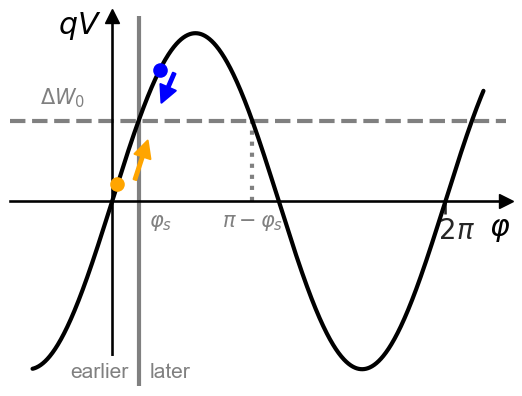

In [5]:
plot_rfwave();

<h3>Transition energy (slide 36)</h3>

<p>Taking the phase slip factor $\eta$ into account, the longitudinal one-turn map of a synchrotron is given by<br />
$z_{n+1}=z_n-\eta C\left(\frac{\Delta p}{p_0}\right)$<br />
$\left(\Delta p\right)_{n+1}=\left(\Delta p\right)_n+\frac{qV}{\left(\beta c\right)_n}\left(\sin\left(\varphi_s-\frac{2\pi}{C}\cdot hz_{n+1}\right)-\sin\left(\varphi_s\right)\right)$<br />
Thus, the phase focusing effect depends on the sign of $\eta$, which is $\eta < 0$ if the energy of the particles is below the transition energy $\gamma<\gamma_t$ and $\eta > 0$ if $\gamma>\gamma_t$. In the function plot_rfwave(), these cases are implemented as "regime='classical'" and "regime='relativistic'", respectively.</p>

<p>Phase focusing for $\gamma<\gamma_\text{t} \Rightarrow \eta<0$ at $\varphi_s=0.5$:</p>

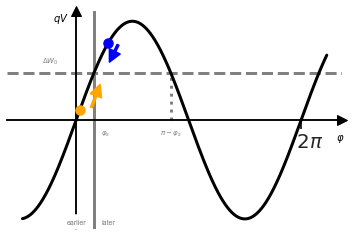

In [3]:
plot_rfwave(phi_s=0.5, regime='classical');

<p>Defocusing for $\gamma<\gamma_\text{t} \Rightarrow \eta<0$ at $\varphi_s=\pi-0.5$:</p>

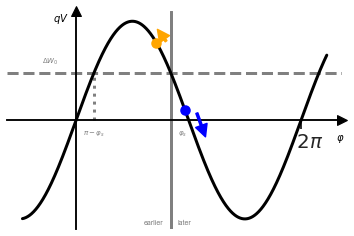

In [4]:
plot_rfwave(phi_s=np.pi-0.5, regime='classical');

<p>Defocusing for $\gamma>\gamma_\text{t} \Rightarrow \eta>0$ at $\varphi_s=0.5$:</p>

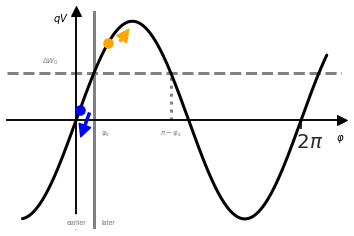

In [5]:
plot_rfwave(phi_s=0.5, regime='relativistic');

<p>Phase focusing for $\gamma>\gamma_\text{t} \Rightarrow \eta>0$ at $\varphi_s=\pi-0.5$:</p>

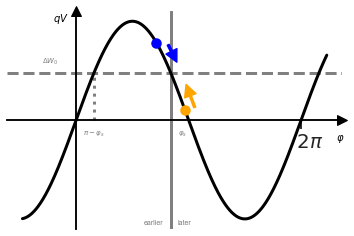

In [6]:
plot_rfwave(phi_s=np.pi-0.5, regime='relativistic');

If the progress bar by `tqdm` (`trange`) later in this document does not work, run this:

In [ ]:
!jupyter nbextension enable --py widgetsnbextension

<h2 style="color:darkred">Tasks: Particle tracking in the CERN Proton Synchrotron</h2>

<h3>Machine parameters for this exercise</h3>

The CERN Proton Synchrotron (PS):
- has a circumference of 2π·100m
- takes protons from the PS Booster at a kinetic energy of 2GeV corresponding to a $\gamma=3.13$
- injects with 50kV of rf voltage, up to 200kV for ramp
- runs at harmonic $h=7$
- has a momentum compaction factor of $\alpha_c=0.027$
- typical acceleration rate of (up to) $\dot{B}=2$ T/s, the bending radius is $\rho=70.08$ m

<h3 style="color: darkred">Tasks based on topics of week 4</h3>

<div style="color:darkred; margin-top: 2em;">Based on the CERN Proton Synchrotron (PS) machine parameters (see above): <br />

1. Track particles given a stationary synchronous particle ($\varphi_s=0$).
2. Determine the frequency of the synchrotron motion (via NAFF).
3. Track particles given an accelerating synchronous particle ($\varphi_s>0$).
4. Compute the transition energy $\gamma_{\text{t}}$ for CERN PS.
4. Set machine energy ($\gamma$) above transition / relativistic regime, track like (4) again.

$\implies$ take note of the observed trajectories in phase space (for the following)!
</div>
<!-- 
3. Derivation of Hamiltonian $\mathcal{H}(z,\delta)=T(\delta) + V(z)$ for stationary synchronous particle ($\varphi_s=0$) -->

<h3>Helper functions and classes</h3>

Some convenience functions to compute the speed β and the relativistic Lorentz factor γ:

In [ ]:
def beta(gamma: float) -> float:
    '''Speed β in units of c from relativistic Lorentz factor γ.'''
    return np.sqrt(1 - gamma**-2)

def gamma(p: float) -> float:
    '''Relativistic Lorentz factor γ from total momentum p.'''
    return np.sqrt(1 + (p / (mass * c))**2)

def p_from_gamma(gamma: float) -> float:
    '''Total momentum p from relativistic Lorentz factor γ.'''
    return mass * c * np.sqrt(gamma**2 - 1)

We gather all the machine parameters in a class named `Machine`.

A `Machine` instance knows
- at which energy the synchronous particle (reference γ, `gamma_ref`, or alternatively the momentum `p0()`) currently runs,
- what the acceleration rate is in terms of the synchronous phase φ_s, `phi_s`
- how to compute the phase-slip factor $\eta$, `eta`, for a particle at a certain momentum p0 + Δp
- how to update the energy of the synchronous particle via `update_gamma_ref()` when a turn has passed

In [ ]:
charge = e
mass = m_p

class Machine(object):
    gamma_ref = 3.13
    circumference = 2*np.pi*100
    voltage = 50e3
    harmonic = 7
    alpha_c = 0.027
    phi_s = 0
    
    def __init__(self, gamma_ref: float = gamma_ref, circumference: float = circumference,
                 voltage: float = voltage, harmonic: int = harmonic, 
                 alpha_c: float = alpha_c, phi_s: float = phi_s) -> None:
        '''Override default settings by giving explicit arguments.'''
        self.gamma_ref = gamma_ref
        self.circumference = circumference
        self.voltage = voltage
        self.harmonic = harmonic
        self.alpha_c = alpha_c
        self.phi_s = phi_s
    
    def eta(self, deltap: float) -> float:
        '''Phase-slip factor for a particle.'''
        p = self.p0() + deltap
        return self.alpha_c - gamma(p)**-2

    def p0(self) -> float:
        '''Momentum of synchronous particle.'''
        return self.gamma_ref * beta(self.gamma_ref) * mass * c

    def update_gamma_ref(self) -> None:
        '''Advance the energy of the synchronous particle
        according to the synchronous phase by one turn.
        '''
        deltap_per_turn = charge * self.voltage / (
            beta(self.gamma_ref) * c) * np.sin(self.phi_s)
        new_p0 = self.p0() + deltap_per_turn
        self.gamma_ref = gamma(new_p0)

To compute a synchronous phase, you may use these convenience functions to compute the $\arcsin$ on the interval of [-π/2,π/2] .

Remember you may likely want to find a synchronous phase on $\varphi_s\in[0,π]$ !

In [ ]:
def deltap_per_turn(Bdot: float, rho: float, circumference: float, p0: float) -> float:
    Trev = circumference / (beta(gamma(p0)) * c)
    return Bdot * rho * charge * Trev

In [ ]:
def compute_phi_s(deltap_per_turn: float, p0: float, voltage: float) -> float:
    '''Return *first* positive phase which matches the
    given Δp/turn on the interval [0, π/2].
    Do check whether you need to use π-φ_s for stability!
    '''
    return np.arcsin(
        deltap_per_turn * beta(gamma(p0)) * c / (charge * voltage)
    )

<h3>Tracking</h3>

The tracking equations for the longitudinal plane read:

$$\begin{cases}\,
    z_{n+1} &= z_n - \eta C \left(\cfrac{\Delta p}{p_0}\right)_n \\
    (\Delta p)_{n+1} &= (\Delta p)_n + \cfrac{q V}{(\beta c)_n}\cdot\left(\sin\left(\varphi_s - \cfrac{2\pi}{C}\cdot hz_{n+1}\right) - \sin(\varphi_s)\right)
\end{cases}$$

<p style="color:darkred">Please implement them with a leapfrog (half-drift + kick + half-drift) scheme.</p>

In [ ]:
def track_one_turn(z_n, deltap_n, machine):
    m = machine # all machine parameters are provided by m.circumference etc
    
    # half drift
    z_nhalf = ... ## to be implemented, you can use m.eta(deltap_n) and m.p0()
    
    # rf kick
    deltap_n1 = ... ## to be implemented, you can use the helper functions beta(gamma) and gamma(m.p0))

    # update reference energy
    m.update_gamma_ref()
    
    # half drift
    z_n1 = ... ## to be implemented
    return z_n1, deltap_n1

<h4>1. Track particles given a stationary synchronous particle</h4>
The `Machine` instance will keep track of the reference energy during the tracking by calling `update_gamma_ref()` once per turn:

In [ ]:
m = Machine()

Particles are tracked by their two longitudinal coordinates $(z, \Delta p)$. The initial values are stored in `z_ini` and `deltap_ini` as `numpy.array`s. These should have `N` entries for $N$ particles.

(You may use numpy helper functions such as `np.linspace` or `np.arange` for convenient initialisation!)

<p style="color:darkred">Please initialise a particle distribution with 40 particles at $z=0$ and evenly spaced $\Delta p$ over the intervall $\left[0,0.01\cdot\textrm{m.p0()}\right]$.</p>

In [ ]:
n_turns = 3000
deltap_ini = ... ## to be implemented
z_ini = np.zeros_like(deltap_ini)

In [ ]:
N = len(z_ini)
assert (N == len(deltap_ini))

To store the coordinate values during tracking, prepare some `n_turns` long 2D arrays with `N` entries per turn:

In [ ]:
z = np.zeros((n_turns, N), dtype=np.float64)
deltap = np.zeros_like(z)

z[0] = z_ini
deltap[0] = deltap_ini

We would also like to store the reference gamma for each turn:

In [ ]:
gammas = np.zeros(n_turns, dtype=np.float64)
gammas[0] = m.gamma_ref

<p style="color:darkred">Let's go, here you can add the tracking loop over the number of turns `n_turns`!</p>

In [ ]:
for i_turn in range(1, n_turns):
    z[i_turn], deltap[i_turn] = ... ## to be implemented using the function track_one_turn(z_n, deltap_n, machine)
    gammas[i_turn] = m.gamma_ref

As a first check, we plot the reference energy over all turns (should be constant for a stationary synchronous particle).

In [ ]:
plt.plot(gammas)
plt.xlabel('Turns')
plt.ylabel('$\gamma_{ref}$')
plt.show()

Let's have a look on the phase space evolution:

In [ ]:
plt.scatter(z, deltap / m.p0(), marker='.', s=0.5)
plt.xlim(-50,100)
plt.xlabel('$z$ [m]')
plt.ylabel('$\Delta p/p_0$')
plt.show()

<h4>2. Determine the frequency of the synchrotron motion (via NAFF).</h4>

In order to visualize the oscillations, we plot the particle positions over turns:

In [ ]:
plt.plot(((z.T)[:19]).T)
plt.xlabel('turns')
plt.ylabel('$z$ [m]')
plt.show()

<p style="color:darkred">Please implement how to determine the spectrum using NAFF.</p>

In [ ]:
freqs_naff = []

... ## to be implemented (compare nmap3.ipynb)

freqs_naff = np.array(freqs_naff)

The results are plotted:

In [ ]:
plt.plot(np.max(((z.T)[:19]).T,axis=0), freqs_naff, c='r', marker='.')

#plt.xticks([-np.pi/2, 0, np.pi/2, np.pi], [r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
plt.xlabel(r'Maximum amplitude z [m]')
plt.ylabel('Phase advance / \n' + r'integration step $\Delta t$ [$2\pi$]');

<h4>3. Track particles given an accelerating synchronous particle ($\gamma=3.13$, typical acceleration rate of $\dot{B}=2$ T/s, bending radius $\rho=70.08$ m, rf voltage 200kV)</h4>

<p style="color:darkred">For the machine initialisation, we need to know the synchronous phase for the given acceleration ramp. Please calculate this phase using the function `compute_phi_s()` above.</p>

In [ ]:
phi_s=compute_phi_s( ... ) ## arguments to be implemented
phi_s

Now we can initialize the machine and set up the initial phase space:

In [ ]:
m = Machine(phi_s=phi_s)

In [ ]:
n_turns = 1000
deltap_ini = np.linspace(0, 0.01 * m.p0(), 40)#np.array([0.]) #np.linspace(start, end, 20)
z_ini = np.zeros_like(deltap_ini)

In [ ]:
N = len(z_ini)
assert (N == len(deltap_ini))

In [ ]:
z = np.zeros((n_turns, N), dtype=np.float64)
deltap = np.zeros_like(z)

z[0] = z_ini
deltap[0] = deltap_ini

In [ ]:
gammas = np.zeros(n_turns, dtype=np.float64)
gammas[0] = m.gamma_ref

Tracking like before:

In [ ]:
for i_turn in range(1, n_turns):
    z[i_turn], deltap[i_turn] = track_one_turn(z[i_turn - 1], deltap[i_turn - 1], m)
    gammas[i_turn] = m.gamma_ref

The reference energy should now increase according to the acceleration ramp:

In [ ]:
plt.plot(gammas)
plt.xlabel('Turns')
plt.ylabel('$\gamma_{ref}$')
plt.show()

And the resulting phase space looks like this:

In [ ]:
plt.scatter(z, deltap / m.p0(), marker='.', s=0.5)
plt.xlabel('$z$ [m]')
plt.ylabel('$\Delta p/p_0$')
plt.show()

<h4 style="color:darkred">4. Compute the transition energy for CERN PS</h4>

In [ ]:
gamma_t = ... ## to be implemented
gamma_t

<h4>5. Set machine energy above transition / relativistic regime, track again.</h4>

<b>For the same synchronous phase we expect longitudinal defocusing of the particle distribution. Let's show this in the tracking.</b>

Same steps as before: machine and phase space initialization, tracking and plotting:

In [ ]:
m = Machine(gamma_ref=7,phi_s=phi_s)

In [ ]:
n_turns = 5000
deltap_ini = np.linspace(0, 0.01 * m.p0(), 40)#np.array([0.]) #np.linspace(start, end, 20)
z_ini = np.zeros_like(deltap_ini)

In [ ]:
N = len(z_ini)
assert (N == len(deltap_ini))

In [ ]:
z = np.zeros((n_turns, N), dtype=np.float64)
deltap = np.zeros_like(z)

z[0] = z_ini
deltap[0] = deltap_ini

In [ ]:
gammas = np.zeros(n_turns, dtype=np.float64)
gammas[0] = m.gamma_ref

In [ ]:
for i_turn in range(1, n_turns):
    z[i_turn], deltap[i_turn] = track_one_turn(z[i_turn - 1], deltap[i_turn - 1], m)
    gammas[i_turn] = m.gamma_ref

In [ ]:
plt.plot(gammas)
plt.xlabel('Turns')
plt.ylabel('$\gamma_{ref}$')
plt.show()

In [ ]:
plt.scatter(z, deltap / m.p0(), marker='.', s=0.5)
plt.xlabel('$z$ [m]')
plt.ylabel('$\Delta p/p_0$')
plt.show()

As expected, all particles are on unstable trajectories.<br /><br />
<b style="color:darkred">Let's change the synchronous phase to longitudinal focusing!</b><br />
<span style="color:darkred">What synchronous phase is required for this?</span>

In [ ]:
m = Machine(gamma_ref=7,phi_s= ... )

In [ ]:
n_turns = 10000
deltap_ini = np.linspace(0, 0.01 * m.p0(), 40)#np.array([0.]) #np.linspace(start, end, 20)
z_ini = np.zeros_like(deltap_ini)

In [ ]:
N = len(z_ini)
assert (N == len(deltap_ini))

In [ ]:
z = np.zeros((n_turns, N), dtype=np.float64)
deltap = np.zeros_like(z)

z[0] = z_ini
deltap[0] = deltap_ini

In [ ]:
gammas = np.zeros(n_turns, dtype=np.float64)
gammas[0] = m.gamma_ref

In [ ]:
for i_turn in range(1, n_turns):
    z[i_turn], deltap[i_turn] = track_one_turn(z[i_turn - 1], deltap[i_turn - 1], m)
    gammas[i_turn] = m.gamma_ref

In [ ]:
plt.plot(gammas)
plt.xlabel('Turns')
plt.ylabel('$\gamma_{ref}$')
plt.show()

In [ ]:
plt.scatter(z, deltap / m.p0(), marker='.', s=0.5)
plt.xlim(right=100)
plt.ylim(bottom=-0.02)
plt.xlabel('$z$ [m]')
plt.ylabel('$\Delta p/p_0$')
plt.show()